<div dir="rtl">

# نوت‌بوک ۳: ممیزی چندوجهی

**فاز ۱، تسک ۶**

مسیر آمازون یک «مسیر چندوجهی» است: برای نمره‌ی اضافه باید **دست‌کم دو منبع اطلاعاتی متمایز** را به‌شکل معنادار در تحلیل ترکیب کنیم. سند می‌گوید چسباندن چند ستون به یک جدول، تحلیل چندوجهی حساب نمی‌شود.

این نوت‌بوک به سه سؤال سند جواب می‌دهد:

۱. برای هر نمونه چه اطلاعاتی در دسترس است: متن، امتیاز، اطلاعات محصول، تصویر، زمان، تعامل کاربر و کالا؟
۲. هر وجه برای چند درصد نمونه‌ها موجود است؟
۳. نبودن یک وجه (مثلاً قیمت یا تصویر) **تصادفی** است یا به چیزی مثل زیرشاخه، سن محصول یا زمان وابسته است؟

در پایان، گزینه‌های «وجه دوم» را کنار هم می‌گذاریم تا انتخاب کنیم.

</div>

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = yaml.safe_load(open(ROOT / "configs" / "config.yaml", encoding="utf-8"))
PROC = ROOT / cfg["data"]["processed_dir"]
FIG = ROOT / "figures"
REP = ROOT / "reports" / "phase1"

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

# single-hue style for all figures in this notebook
BAR = "#3B6EA8"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9,
})

reviews = pd.read_parquet(PROC / "reviews_rc.parquet")
meta = pd.read_parquet(PROC / "meta_rc.parquet")

# helper columns
meta["cat_level3"] = meta["categories"].map(
    lambda c: (json.loads(c) + [None, None, None])[2] or "(none)")
first_ts = reviews.groupby("parent_asin")["timestamp"].min()
meta["first_review_year"] = pd.to_datetime(meta["parent_asin"].map(first_ts), unit="ms").dt.year
meta["n_reviews"] = meta["parent_asin"].map(reviews.groupby("parent_asin").size()).fillna(0).astype(int)
reviews["year"] = pd.to_datetime(reviews["timestamp"], unit="ms").dt.year
print(f"reviews: {len(reviews):,}   products: {len(meta):,}")

reviews: 862,444   products: 71,046


<div dir="rtl">

## ۱. فهرست وجه‌ها

هر نقد به‌طور مستقیم یا از طریق محصولش (با `parent_asin`) به این منابع دسترسی دارد:

| وجه | از کجا | ستون‌ها | سطح |
|---|---|---|---|
| متن نقد | فایل نقدها | `title`، `text` | نقد |
| امتیاز | فایل نقدها | `rating` | نقد (**متغیر هدف**) |
| تصویر نقد | فایل نقدها | `images` | نقد |
| زمان | فایل نقدها | `timestamp` | نقد |
| تعامل کاربر و کالا | فایل نقدها | `user_id`، `verified_purchase`، `helpful_vote` | نقد |
| اطلاعات ساخت‌یافته‌ی محصول | فایل محصول | `price`، `store`، `categories`، `details` | محصول |
| متن فروشنده | فایل محصول | `title`، `features`، `description` | محصول |
| تصویر و ویدیوی محصول | فایل محصول | `images`، `videos` | محصول |

نکته‌ی مهم: وجه‌های «سطح محصول» برای همه‌ی نقدهای یک محصول **یکسان‌اند**. یعنی با آن‌ها نمی‌شود فهمید چرا یک مشتری ۵ ستاره داده و دیگری ۱ ستاره برای همان محصول؛ فقط تفاوت بین محصولات را نشان می‌دهند.

</div>

<div dir="rtl">

## ۲. دسترس‌پذیری هر وجه

درصد نمونه‌هایی که هر وجه را **با محتوای واقعی** دارند. در سطح نقد، وجه‌های محصول از طریق اتصال به محصول حساب شده‌اند.

</div>

In [2]:
def nonempty_json(s):
    return s.notna() & ~s.fillna("").str.strip().isin(["", "[]", "{}"])

prod = pd.DataFrame({
    "parent_asin": meta["parent_asin"],
    "price": meta["price"].notna(),
    "store": meta["store"].notna() & (meta["store"].str.strip() != ""),
    "category path": nonempty_json(meta["categories"]),
    "details": nonempty_json(meta["details"]),
    "seller features": nonempty_json(meta["features"]),
    "seller description": nonempty_json(meta["description"]),
    "product images": meta["n_images"].fillna(0) > 0,
    "product videos": meta["n_videos"].fillna(0) > 0,
}).set_index("parent_asin")

rev = pd.DataFrame({
    "review text": reviews["text"].str.strip().str.len() > 0,
    "rating": reviews["rating"].notna(),
    "time": reviews["timestamp"].notna(),
    "review images": reviews["n_images"] > 0,
    "verified purchase flag": reviews["verified_purchase"].notna(),
})
rev = rev.join(prod.reindex(reviews["parent_asin"]).reset_index(drop=True))

availability = pd.DataFrame({
    "% of reviews": (100 * rev.mean()).round(1),
    "% of products": (100 * prod.mean()).round(1).reindex(rev.columns),
})
availability.sort_values("% of reviews", ascending=False)

,% of reviews,% of products
rating,100.0,NaN
verified purchase flag,100.0,NaN
time,100.0,NaN
product images,100.0,100.0
category path,100.0,100.0
store,99.9,99.8
review text,99.9,NaN
details,98.4,97.5
seller features,92.4,82.4
product videos,64.2,27.5


<div dir="rtl">

تفاوت دو ستون مهم است. مثلاً اگر قیمت در «سطح نقد» بیشتر از «سطح محصول» موجود باشد، یعنی محصولات پرنقد بیشتر قیمت دارند؛ یعنی گمشدگی قیمت به محبوبیت محصول وابسته است.

</div>

<div dir="rtl">

## ۳. آیا نبودن قیمت تصادفی است؟

اگر قیمت **تصادفی** گم شده باشد، سهم محصولات بی‌قیمت در همه‌ی گروه‌ها باید تقریباً یکسان باشد. سه گروه‌بندی را امتحان می‌کنیم:

- **زیرشاخه:** وسیله، قطعه، پهپاد و ...
- **سن محصول:** سال اولین نقد محصول
- **محبوبیت:** تعداد نقدهای محصول

</div>

In [3]:
meta["price_missing"] = meta["price"].isna()

by_cat = (meta.groupby("cat_level3")["price_missing"]
              .agg(missing_share="mean", products="size")
              .query("products >= 300")
              .sort_values("missing_share"))

year_bins = meta.dropna(subset=["first_review_year"])
year_bins = year_bins[year_bins["first_review_year"] >= 2010]
by_year = year_bins.groupby("first_review_year")["price_missing"].agg(missing_share="mean", products="size")

pop_bins = pd.cut(meta["n_reviews"], [0, 1, 5, 20, 100, np.inf],
                  labels=["1", "2-5", "6-20", "21-100", "100+"])
by_pop = meta.groupby(pop_bins, observed=True)["price_missing"].agg(missing_share="mean", products="size")

overall = meta["price_missing"].mean()
print(f"overall share of products without price: {overall:.1%}")
display((100 * by_cat["missing_share"]).round(1).to_frame("% without price").join(by_cat["products"]))
display((100 * by_pop["missing_share"]).round(1).to_frame("% without price").join(by_pop["products"]))

overall share of products without price: 48.3%


,% without price,products
cat_level3,,
Vehicle Bodies & Scale Accessories,28.3,4105
Transmissions & Differentials,29.8,965
Suspension Systems & Parts,32.0,328
Power Plant & Driveline Systems,34.4,6632
Combustion Engines & Parts,44.8,796
Remote & App Controlled Vehicle Parts,46.1,35506
(none),54.6,807
Electric Motors & Parts,54.8,2158
Robots,55.6,657


,% without price,products
n_reviews,,
1,53.4,27228
2-5,47.0,24245
6-20,43.1,13095
21-100,42.2,5326
100+,39.7,1149


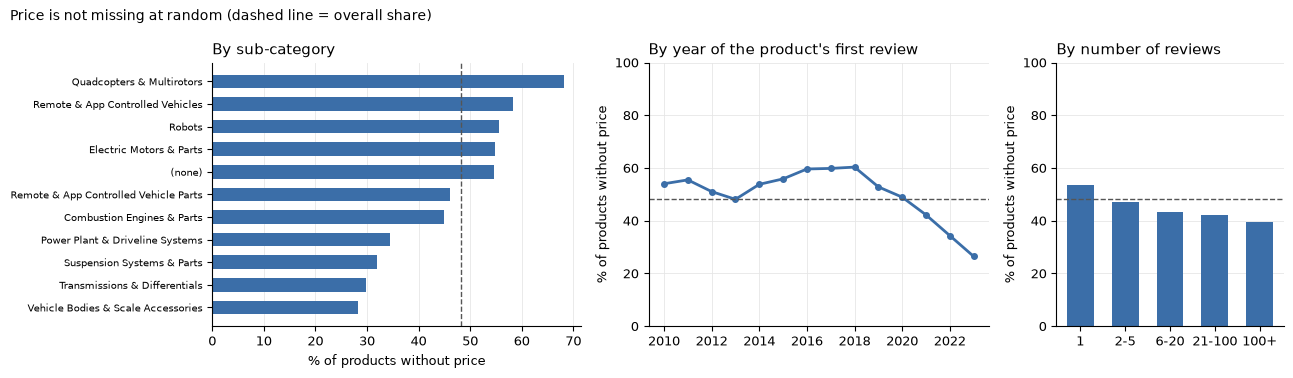

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.3, 1.2, 0.8]})

ax = axes[0]
ax.barh(by_cat.index, 100 * by_cat["missing_share"], color=BAR, height=0.6)
ax.axvline(100 * overall, color="#555", lw=1, ls="--")
ax.set_title("By sub-category", loc="left")
ax.set_xlabel("% of products without price")
ax.tick_params(axis="y", labelsize=7.5)
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.plot(by_year.index, 100 * by_year["missing_share"], color=BAR, lw=2, marker="o", ms=4)
ax.axhline(100 * overall, color="#555", lw=1, ls="--")
ax.set_title("By year of the product's first review", loc="left")
ax.set_ylabel("% of products without price")
ax.set_ylim(0, 100)

ax = axes[2]
ax.bar(by_pop.index.astype(str), 100 * by_pop["missing_share"], color=BAR, width=0.6)
ax.axhline(100 * overall, color="#555", lw=1, ls="--")
ax.set_title("By number of reviews", loc="left")
ax.set_ylabel("% of products without price")
ax.set_ylim(0, 100)
ax.grid(axis="x", visible=False)

fig.suptitle("Price is not missing at random (dashed line = overall share)", x=0.01, ha="left", fontsize=10)
plt.tight_layout()
plt.savefig(FIG / "fig03_price_missingness.png", dpi=200, bbox_inches="tight")
plt.show()

<div dir="rtl">

**تفسیر:** سهم محصولات بی‌قیمت بین زیرشاخه‌ها، سال‌ها و سطوح محبوبیت به‌وضوح فرق می‌کند؛ پس گمشدگی قیمت **تصادفی نیست**.

یک توضیح محتمل: قیمت در سال ۲۰۲۳ از صفحه‌ی محصول برداشته شده است. محصولی که دیگر فروخته نمی‌شود (قدیمی یا کم‌فروش) احتمالاً در آن زمان قیمتی نداشته است. این یک **فرضیه** است، نه واقعیت ثابت‌شده.

**پیامد:** اگر محصولات بی‌قیمت را حذف کنیم، زیرمجموعه به سمت محصولات جدیدتر و پرفروش‌تر کج می‌شود. اگر قیمت را در مدل استفاده کنیم، باید «نداشتن قیمت» را هم به‌صورت یک ویژگی جدا (بله/خیر) وارد کنیم، چون خودش اطلاعات دارد.

</div>

<div dir="rtl">

## ۴. آیا گذاشتن تصویر در نقد تصادفی است؟

دو سؤال: آیا مشتری‌های ناراضی بیشتر عکس می‌گذارند (مثلاً از قطعه‌ی شکسته)؟ و آیا سهم نقدهای تصویردار در طول زمان عوض شده است؟

</div>

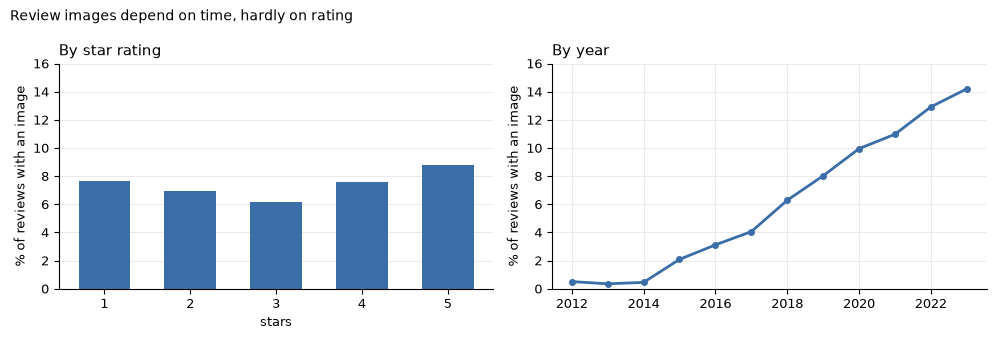

rating
1.0    7.7
2.0    6.9
3.0    6.2
4.0    7.6
5.0    8.8


In [5]:
reviews["has_image"] = reviews["n_images"] > 0
img_by_rating = reviews.groupby("rating")["has_image"].mean()
img_by_year = reviews[reviews["year"] >= 2012].groupby("year")["has_image"].mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
ax.bar(img_by_rating.index.astype(int).astype(str), 100 * img_by_rating, color=BAR, width=0.6)
ax.set_title("By star rating", loc="left")
ax.set_xlabel("stars")
ax.set_ylabel("% of reviews with an image")
ax.set_ylim(0, 16)
ax.grid(axis="x", visible=False)

ax = axes[1]
ax.plot(img_by_year.index, 100 * img_by_year, color=BAR, lw=2, marker="o", ms=4)
ax.set_title("By year", loc="left")
ax.set_ylabel("% of reviews with an image")
ax.set_ylim(0, 16)

fig.suptitle("Review images depend on time, hardly on rating", x=0.01, ha="left", fontsize=10)
plt.tight_layout()
plt.savefig(FIG / "fig04_review_images.png", dpi=200, bbox_inches="tight")
plt.show()

print((100 * img_by_rating).round(1).to_string())

<div dir="rtl">

**تفسیر:** سهم نقدهای تصویردار تقریباً به امتیاز بستگی ندارد، ولی در طول زمان از تقریباً صفر به بیش از ۱۰٪ رسیده است؛ احتمالاً چون آمازون امکان افزودن تصویر را تدریجی‌تر و ساده‌تر کرده است. پس **وجود تصویر بیشتر نشانه‌ی زمان نقد است تا نظر مشتری**. اگر آن را بی‌احتیاط به مدل بدهیم، مدل ممکن است به‌جای کیفیت محصول، «زمان» را یاد بگیرد.

</div>

<div dir="rtl">

## ۵. گزینه‌های وجه دوم

وجه اصلی ما **متن نقد** است: جنبه‌ها از آن استخراج می‌شوند و ۹۹٫۹٪ نقدها آن را دارند. برای نمره‌ی اضافه دست‌کم یک منبع متمایز دیگر لازم است:

| گزینه | دسترس‌پذیری | ارتباط با سؤال ما | هزینه | خطر |
|---|---|---|---|---|
| **زمان** | ۱۰۰٪ نقدها | زیاد: سؤال ما خودش روی بازه‌های زمانی است | کم | داده‌ی ناقص ۲۰۲۳ |
| **اطلاعات ساخت‌یافته‌ی محصول** (زیرشاخه، قیمت، فروشگاه) | زیرشاخه ۱۰۰٪، قیمت حدود ۶۰٪ نقدها | متوسط: شکایت‌های یک پهپاد گران با یک قطعه‌ی ارزان فرق دارد | کم | گمشدگی غیرتصادفی قیمت؛ خطای برچسب زیرشاخه |
| **تصویر محصول** | ۱۰۰٪ محصولات | کم تا متوسط: ظاهر محصول، نه تجربه‌ی مشتری | زیاد (نیاز به مدل تصویری و GPU) | برای همه‌ی نقدهای یک محصول یکسان است |
| **تصویر نقد** | حدود ۸٪ نقدها | متوسط: می‌تواند خرابی را نشان دهد | زیاد | خیلی کم و وابسته به زمان |
| **متن فروشنده** (ویژگی‌ها، توضیحات) | حدود ۷۰ تا ۸۰٪ محصولات | متوسط: ادعای فروشنده در برابر تجربه‌ی مشتری | متوسط | برای همه‌ی نقدهای یک محصول یکسان است |

انتخاب نهایی وجه دوم در کارت پروژه ثبت می‌شود.

</div>

<div dir="rtl">

## ۶. جمع‌بندی

**دسترس‌پذیری:** متن نقد (۹۹٫۹٪)، امتیاز، زمان و زیرشاخه‌ی محصول (۱۰۰٪) تقریباً برای همه‌ی نقدها موجودند. قیمت برای ۶۲٪ نقدها و ۵۲٪ محصولات، و تصویر نقد فقط برای ۸٪ نقدها وجود دارد. اختلاف درصد «سطح نقد» و «سطح محصول» نشان می‌دهد محصولات پرنقد بیشتر قیمت و ویدیو دارند.

**گمشدگی قیمت تصادفی نیست:** سهم محصولات بی‌قیمت از ۲۸٪ (بدنه‌ی خودرو) تا ۶۸٪ (پهپادها) متغیر است، برای محصولاتی که اولین نقدشان حدود ۲۰۱۸ بوده به ۶۰٪ و برای محصولات ۲۰۲۳ به ۲۷٪ می‌رسد، و با افزایش تعداد نقد کم می‌شود. فرضیه: قیمت در ۲۰۲۳ برداشته شده و محصولاتی که دیگر فروخته نمی‌شدند قیمتی نداشته‌اند. **پیامد:** محصولات بی‌قیمت حذف نمی‌شوند (حذف، داده را به سمت محصولات جدید و پرفروش کج می‌کند) و «نداشتن قیمت» به‌صورت ویژگی جدا وارد مدل می‌شود.

**تصویر نقد به زمان وابسته است، نه به رضایت:** سهم نقدهای تصویردار بین امتیازها تقریباً ثابت است (۶ تا ۹٪) ولی از کمتر از ۱٪ در ۲۰۱۴ به ۱۴٪ در ۲۰۲۳ رسیده است. استفاده از آن، خطر یادگیری «سال نقد» به‌جای کیفیت محصول را دارد.

**تصمیم وجه‌ها:** متن نقد (وجه اصلی) + زمان + اطلاعات ساخت‌یافته‌ی محصول (زیرشاخه، قیمت با نشانگر گمشدگی، فروشگاه). تصویر نقد کنار گذاشته شد؛ تصویر محصول در صورت وجود وقت، آزمایش تکمیلی فاز ۳ است. جزئیات در بند ۱۳ کارت پروژه.

</div>